# 第 14 步：连续估值与第二次月度调仓

<!-- SNAPSHOT_NOTE -->

## 数据准备说明

本页记录完整快照上的实际运行。通过 GitHub 克隆源码后，先在仓库根目录运行 `python publication/restore_snapshot.py`，恢复同版本的 `data/` 与 `runs/`，再执行本步。[完整数据与大型结果索引](../../publication/ASSET_INDEX.md)保留全部路径和哈希；本页图表与 Notebook 已保存输出可直接阅读。

## 目标：从一笔交易走向连续账户

第 13 步已经买入十只人工股票。本步保留同一个账户，月末重新选出的名单只是目标，需要经过执行才能成为持仓。账户从 2020-01-31 的持币状态开始，保留 2020-02-03 首次买入后的数量，逐日按收盘价估值，直到 2020-02-28 收盘产生第二个信号，并在 2020-03-02 开盘先卖后买。

这一阶段，我重点关注三个问题：没有交易的日子为什么也会有收益；保留下来的股票为什么仍可能发生买卖；旧股票卖不出去时，新目标能否按计划全部实现。为此，同时保留基准场景与一个明确标注的人为拒卖场景，将反事实状态和原始行情分开。

## 输入、命令与输出位置

沿用 [固定模拟配置](../../configs/baseline.json)、[同一输入快照](../../runs/first_demo_20261107/input/metadata.json)和[第 12 步目标名单](../../runs/first_demo_20261107/lesson12_equal_weight_selection/target_portfolio.csv)，在仓库根目录运行：

```powershell
.\.venv\Scripts\python.exe examples/13_first_execution.py
.\.venv\Scripts\python.exe examples/14_daily_valuation_rebalance.py
```

新环境先完成 `-r requirements-tested.txt -e ".[plots]"` 的安装。第 14 步会重新用同一引擎生成这段连续账户，并与首次目标保持一致；它不修改第 13 步结果。主要结果位于 `runs/first_demo_20261107/lesson14_daily_rebalance/`，反事实结果单独放在 `blocked_sell_demo/`。

![连续净值与两次执行](../../runs/first_demo_20261107/lesson14_daily_rebalance/daily_nav.png)

这张图展示每日收盘账户净值，不表示每天都按图上的点成交。图上只有两个开盘执行事件，其他节点主要反映已持仓的价格变化。人工日历包含真实市场假日，因此这些日期不能照搬为真实 A 股交易安排。

## 每日估值公式

设前一收盘权益为 (E_{t-1}^c)，当日开盘前现金为 (C_{t-1})，旧数量为 (q_{i,t-1})。先用当日开盘价标记旧仓：

$$
E_t^{before}=C_{t-1}+\sum_iq_{i,t-1}P_{i,t}^{o}.
$$

这个权益已经包含旧仓从上一收盘到本日开盘的隔夜变化。执行结束后，现金为 (C_t)，新数量为 (q_{i,t})，再用收盘价估值：

$$
E_t^c=C_t+\sum_iq_{i,t}P_{i,t}^c,\qquad
r_t=\frac{E_t^c}{E_{t-1}^c}-1.
$$

不调仓时，数量保持不变，但股票价格变化仍会改变市值、净值和权重。把数量固定与权重固定混为一谈，会引入没有记录的每日再平衡。

一天的损益还可以进一步分解为：

$$
E_t^c=E_{t-1}^c+
\sum_iq_{i,t-1}(P_{i,t}^{o}-P_{i,t-1}^{c})
-Cost_t+
\sum_iq_{i,t}(P_{i,t}^{c}-P_{i,t}^{o}).
$$

第一段价格变化由旧仓承担，最后一段由调仓后的仓位承担。成本包括佣金、卖出税和以原开盘估值衡量的滑点损失。这种分解既避免把新买入股票的买前隔夜收益算入账户，也保留了旧仓承担的隔夜损益。

## 确定第二次目标

脚本通过完整日历的月末序列确定第二次信号，而不是假定每月都有固定 30 天：

```python
signals = monthly_signal_dates(days)
second_signal = signals[signals.get_loc(first_signal) + 1]
second_execution = days[days.get_loc(second_signal) + 1]
```

第一行取得存在下一交易日的完整月末，第二行找到首次信号之后的下一个月末，第三行定位对应开盘执行日。计算因子时仍保留更早的历史和完整日历，不让每个月的 20 日窗口从零开始。

`target_list` 只读取信号日完整分数，按综合分数和代码确定前十名，然后给出目标权重。执行日涨跌、价格和可成交状态都不参与重新挑选排名。遇到受阻股票时，也不能临时换成事后容易成交或上涨的股票。

## 先卖后买的执行顺序

先按调仓前开盘权益为每只新目标计算名义目标市值。再比较旧数量与目标数量：不在目标中的股票申请清仓，保留在目标中但当前市值过高的股票申请部分卖出。卖出获准后，现金只增加实际成交额减佣金与卖出税；失败的卖单不产生现金，旧数量继续存在。

随后计算新买入和保留股票的目标缺口。买单所需现金包含滑点与佣金，资金不足时按同一系数缩量，不借入没有授权的资金。拒单在当天到期，直到下一次月度再平衡才重新产生目标订单；本引擎不自动逐日追单。

目标权重与最终权重要分别计算：前者按调仓前权益定义，后者按实际成交后的权益或当日收盘权益计算。发生费用、价格变化或拒单后，两者通常不会完全相等。

## 还原开盘前、开盘后和收盘三张快照

审计函数把前日数量、当日数量、目标权重和本日价格合并到同一张表。关键计算是：

```python
weights["before_open_value"] = weights["before_quantity"] * weights["adj_open"]
weights["after_open_value"] = weights["after_quantity"] * weights["adj_open"]
weights["after_close_value"] = weights["after_quantity"] * weights["adj_close"]
```

第一行重建旧仓的本日开盘价值，第二行按同一个未加滑点价格标记新仓，第三行计算新仓收盘价值。前后使用相同开盘估值价，才能把执行造成的经济成本分离出来。填零只适用于“不存在旧仓或新仓”的数量；价格缺失则停止核对，不能填零后继续。

现金账的对应代码是：

```python
expected_cash = (previous_day["cash"] + sells["notional"].sum()
                 - buys["notional"].sum() - commission - tax)
```

这行不再扣滑点，因为成交金额已经按含滑点成交价形成。另用“调仓后开盘权益等于调仓前权益减经济成本”核对滑点与费用。

## 第二次调仓结果

[rebalance_summary.json](../../runs/first_demo_20261107/lesson14_daily_rebalance/rebalance_summary.json) 保存了以下实际输出：

| 基准场景核对项 | 2020-03-02 保存值 |
| --- | ---: |
| 前一收盘权益 | 1030850.857157449 |
| 调仓前开盘权益 | 1032009.4044407138 |
| 调仓后开盘权益 | 1030923.9336454762 |
| 当日佣金 | 310.0938177133 |
| 当日卖出税 | 258.5536766347 |
| 当日滑点损失 | 516.8233008898 |
| 当日总成本 | 1085.4707952378 |
| 当日收盘权益 | 1030654.3472429779 |
| 收盘净值 | 1.030654347243 |
| 当日收益 | -0.0190628851% |
| 卖出 / 买入笔数 | 9 / 6 |
| 期末持仓数量 | 10 |

累计净值高于 1，不意味着当天收益一定为正。本日收盘比前一收盘略低，所以日收益为负；此前积累的收益仍使累计净值高于起点。9 笔卖出也不等于换出 9 个代码，其中包含保留股票的部分减仓。

逐行核对可以从 [rebalance_weights.csv](../../runs/first_demo_20261107/lesson14_daily_rebalance/rebalance_weights.csv) 开始，重点查看 `before_quantity`、`after_quantity`、`target_weight`、`quantity_change` 和三种权重。[daily.csv](../../runs/first_demo_20261107/lesson14_daily_rebalance/daily.csv) 共有 22 行，从信号日持币状态连续走到第二次执行日；两次执行之间没有隐藏交易。

## 独立构造拒卖场景

为了观察约束如何影响账户，复制价格表，只将 `SYN034` 在第二次执行日的 `can_sell` 改成 `False`：

```python
modified = prices.copy()
mask = modified["date"].eq(second_execution) & modified["symbol"].eq(blocked_symbol)
modified.loc[mask, "can_sell"] = False
scenario = run_backtest(modified, factors, days, lesson_config)
```

第一行创建独立副本，第二行只定位一只股票的一天，第三行改变卖出权限，第四行用相同信号与规则重新记账。这是人为反事实示例，不代表原始数据中实际发生了停牌或跌停。

[拒卖场景说明](../../runs/first_demo_20261107/lesson14_daily_rebalance/blocked_sell_demo/scenario_note.json) 和[场景汇总](../../runs/first_demo_20261107/lesson14_daily_rebalance/blocked_sell_demo/summary.json)显示：`SYN034` 前后数量都为 `3239.660130387696`，一笔卖单被拒，成交数量为零，也没有对应的卖出成交款。其余订单调整后，最终持有 11 只股票；目标仍是十只，额外一只是无法卖出的旧仓。

拒卖场景只有 8 笔卖出、6 笔买入，成本为 `879.3758568514`，收盘权益为 `1030491.6715845452`，净值为 `1.030491671585`。可供新买入使用的真实卖出净到账约为 `418590.6599065861`，实际买入扣款约为同一金额。引擎没有把本来应卖出的约 9.8 万元虚构成现金，新买单相应缩量。现金约 (10^{-10}) 元的尾数是浮点运算残差，经济上可视为零。

## 误区检查、验收与下一步

目标名单变化不能直接成为删除旧持仓的理由；删除数量却不记录成交，会凭空消灭资产或制造现金。股票仍在前十名，也不意味着无需调整权重；目标十只持仓更不能成为假设受阻旧仓已经清空的依据。已知且提供的状态约束需要落实到成交，但人工旗标的教学结果不等于真实市场流动性模型。

验收包括：第 13 步两行账户与本步相应前缀一致；每日现金加持仓收盘市值等于权益；收益以上一交易日的实际收盘权益为分母；中间没有无记录交易；拒卖场景保留原数量且不增加卖出现金；原始输入文件没有被场景改动。对我而言，这些检查通过后，才有依据把这段连续账户扩展到完整历史。

[完整脚本](../../examples/14_daily_valuation_rebalance.py) · [下一步：完整历史指标](../15_full_history_performance/README.md)

## 完整可运行实现

上面的片段用于解释思路；下面各单元按顺序执行完整脚本。先定位仓库根目录，并显式设置脚本路径，使 `__file__` 在 Notebook 中也有明确含义。

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = next((candidate for candidate in [Path.cwd(), *Path.cwd().parents]
                     if (candidate / "pyproject.toml").exists()
                     and (candidate / "examples/01_read_prices.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("我需要从本项目目录或它的子目录打开 Notebook。")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)
__file__ = str(PROJECT_ROOT / 'examples/14_daily_valuation_rebalance.py')
sys.argv = [__file__]


### 完整实现 · 单元 1

In [2]:
"""第十四课：逐日估值、权重漂移、第二次调仓及明确标注的拒卖示例。"""

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
from ashare_lab.config import load_config
from ashare_lab.data import load_dataset, write_json
from ashare_lab.factors import compute_factors, monthly_signal_dates
from ashare_lab.backtest import run_backtest

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

### 完整实现 · 单元 2

In [3]:
def target_list(factors, signal_date, top_n):
    """只按信号日的完整分数确定名单；没有读取执行日价格或状态。"""
    cross = factors.loc[factors["date"] == signal_date].dropna(subset=["composite"])
    target = cross.sort_values(["composite", "symbol"], ascending=[False, True]).head(top_n).copy()
    if target.empty:
        raise ValueError("信号日没有完整因子，无法生成本课目标名单。")
    target["target_weight"] = 1 / len(target)
    return target

### 完整实现 · 单元 3

In [4]:
def audit_rebalance(result, prices, days, execution_date, targets):
    """还原调仓前开盘、调仓后开盘和收盘三次估值及现金账。"""
    previous_date = days[days.get_loc(execution_date) - 1]
    previous_day = result.daily.loc[result.daily["date"] == previous_date].iloc[0]
    current_day = result.daily.loc[result.daily["date"] == execution_date].iloc[0]
    previous = result.positions.loc[result.positions["date"] == previous_date,
                                    ["symbol", "quantity"]].rename(columns={"quantity": "before_quantity"})
    after = result.positions.loc[result.positions["date"] == execution_date,
                                ["symbol", "quantity"]].rename(columns={"quantity": "after_quantity"})
    symbols = sorted(set(previous["symbol"]) | set(after["symbol"]) | set(targets["symbol"]))
    marks = prices.loc[prices["date"] == execution_date, ["symbol", "adj_open", "adj_close"]]
    weights = pd.DataFrame({"symbol": symbols}).merge(previous, on="symbol", how="left", validate="one_to_one")
    weights = weights.merge(after, on="symbol", how="left", validate="one_to_one")
    weights = weights.merge(targets[["symbol", "target_weight"]], on="symbol", how="left", validate="one_to_one")
    weights = weights.merge(marks, on="symbol", how="left", validate="one_to_one")
    # 这里填零只表示不存在旧持仓/新持仓/目标，不填补任何行情价格。
    for column in ["before_quantity", "after_quantity", "target_weight"]:
        weights[column] = weights[column].fillna(0)
    if weights[["adj_open", "adj_close"]].isna().any().any():
        raise ValueError("核对表缺少价格，不能填价后继续估值。")

    weights["before_open_value"] = weights["before_quantity"] * weights["adj_open"]
    weights["after_open_value"] = weights["after_quantity"] * weights["adj_open"]
    weights["after_close_value"] = weights["after_quantity"] * weights["adj_close"]
    before_open_equity = previous_day["cash"] + weights["before_open_value"].sum()
    after_open_equity = current_day["cash"] + weights["after_open_value"].sum()
    weights["before_open_weight"] = weights["before_open_value"] / before_open_equity
    weights["after_open_weight"] = weights["after_open_value"] / after_open_equity
    weights["after_close_weight"] = weights["after_close_value"] / current_day["equity"]
    weights["target_value_at_open"] = weights["target_weight"] * before_open_equity
    weights["quantity_change"] = weights["after_quantity"] - weights["before_quantity"]

    trades = result.trades.loc[result.trades["date"] == execution_date]
    orders = result.orders.loc[result.orders["date"] == execution_date]
    sells = trades.loc[trades["side"] == "sell"]
    buys = trades.loc[trades["side"] == "buy"]
    commission = trades["commission"].sum()
    tax = trades["tax"].sum()
    slippage = trades["slippage_cost"].sum()
    cost = commission + tax + slippage

    # 现金账只扣成交额、佣金和税；滑点已经体现在成交价，不能再次扣现金。
    expected_cash = (previous_day["cash"] + sells["notional"].sum()
                     - buys["notional"].sum() - commission - tax)
    assert np.isclose(expected_cash, current_day["cash"], rtol=0, atol=1e-7)
    assert np.isclose(after_open_equity, before_open_equity - cost, rtol=0, atol=1e-7)
    assert np.isclose(current_day["equity"], current_day["cash"] + weights["after_close_value"].sum(), rtol=0, atol=1e-7)
    summary = dict(date=str(execution_date.date()), previous_close_equity=float(previous_day["equity"]),
        before_open_equity=float(before_open_equity), after_open_equity=float(after_open_equity),
        close_equity=float(current_day["equity"]), nav=float(current_day["nav"]),
        daily_return=float(current_day["return"]), cash=float(current_day["cash"]),
        commission=float(commission), sell_tax=float(tax), slippage=float(slippage), total_cost=float(cost),
        sell_count=len(sells), buy_count=len(buys), rejected_orders=int(orders["status"].eq("rejected").sum()),
        holdings_count=int(current_day["holdings_count"]))
    ledger = pd.DataFrame([
        ("cash", "调仓前现金", float(previous_day["cash"])),
        ("cash", "卖出成交额", float(sells["notional"].sum())),
        ("cash", "买入成交额", -float(buys["notional"].sum())),
        ("cash", "佣金", -float(commission)),
        ("cash", "卖出税", -float(tax)),
        ("cash_total", "调仓后现金", float(current_day["cash"])),
        ("equity", "调仓前开盘权益", float(before_open_equity)),
        ("equity", "佣金", -float(commission)),
        ("equity", "卖出税", -float(tax)),
        ("equity", "滑点", -float(slippage)),
        ("equity", "调仓后持仓日内市值变化", float(current_day["equity"] - after_open_equity)),
        ("equity_total", "收盘权益", float(current_day["equity"])),
    ], columns=["section", "category", "amount"])
    return weights, ledger, summary

### 完整实现 · 单元 4

In [5]:
def save_result(result, folder):
    folder.mkdir(parents=True, exist_ok=True)
    for name in ["daily", "trades", "orders", "positions"]:
        getattr(result, name).to_csv(folder / f"{name}.csv", index=False, date_format="%Y-%m-%d")
    # 每个交易日核对权益恒等式，价格缺失则由引擎直接报错。
    invested = result.positions.groupby("date")["market_value"].sum().reindex(result.daily["date"], fill_value=0)
    assert np.allclose(result.daily["equity"], result.daily["cash"].to_numpy() + invested.to_numpy(), rtol=0, atol=1e-7)
    assert (result.daily["cash"] >= -1e-7).all()
    assert (result.trades["date"] > result.trades["signal_date"]).all()

### 完整实现 · 单元 5

In [6]:
def main():
    project_dir = Path(__file__).resolve().parents[1]
    run_dir = project_dir / "runs" / "first_demo_20261107"
    prices, universe, days, _ = load_dataset(run_dir / "input")
    config = load_config(project_dir / "configs" / "baseline.json")
    config["calendar_dates"] = days.strftime("%Y-%m-%d").tolist()
    factors = compute_factors(prices, universe, config)

    # 1. 接续上一课目标组合的信号日期，找到第二次月末信号与执行日。
    prior_targets = pd.read_csv(run_dir / "lesson12_equal_weight_selection" / "target_portfolio.csv",
                                dtype={"symbol": "string"}, parse_dates=["date", "execution_date"])
    first_signal = prior_targets["date"].iloc[0]
    signals = monthly_signal_dates(days)
    second_signal = signals[signals.get_loc(first_signal) + 1]
    first_execution = days[days.get_loc(first_signal) + 1]
    second_execution = days[days.get_loc(second_signal) + 1]
    lesson_config = dict(config, start=str(first_signal.date()), end=str(second_execution.date()),
                        splits={"lesson": [str(first_signal.date()), str(second_execution.date())]})

    # 2. 接上已实现的引擎：逐日估值，只有到执行日才先卖后买。
    result = run_backtest(prices, factors, days, lesson_config)
    first_targets = target_list(factors, first_signal, config["top_n"])
    second_targets = target_list(factors, second_signal, config["top_n"])
    assert set(first_targets["symbol"]) == set(prior_targets["symbol"])
    weights, ledger, summary = audit_rebalance(result, prices, days, second_execution, second_targets)
    output_dir = run_dir / "lesson14_daily_rebalance"
    save_result(result, output_dir)
    weights.to_csv(output_dir / "rebalance_weights.csv", index=False)
    ledger.to_csv(output_dir / "rebalance_ledger.csv", index=False)
    second_targets.to_csv(output_dir / "second_signal_targets.csv", index=False, date_format="%Y-%m-%d")
    write_json(output_dir / "rebalance_summary.json", summary)

    # 3. 2 月持仓数量不变；收益、净值和权重随收盘价格变化。
    middle = result.trades.loc[(result.trades["date"] > first_execution) &
                                (result.trades["date"] < second_execution)]
    assert middle.empty

    # 4. 单独的反事实教学示例：复制行情，只禁止 SYN034 在第二执行日卖出。
    # 这不是原始数据中的事件，也不会修改 input/prices.csv。
    removed = sorted(set(first_targets["symbol"]) - set(second_targets["symbol"]))
    blocked_summary = None
    if removed:
        blocked_symbol = "SYN034" if "SYN034" in removed else removed[0]
        modified = prices.copy()
        mask = modified["date"].eq(second_execution) & modified["symbol"].eq(blocked_symbol)
        assert mask.sum() == 1 and bool(modified.loc[mask, "can_sell"].iloc[0])
        modified.loc[mask, "can_sell"] = False
        scenario = run_backtest(modified, factors, days, lesson_config)
        scenario_dir = output_dir / "blocked_sell_demo"
        save_result(scenario, scenario_dir)
        scenario_weights, scenario_ledger, blocked_summary = audit_rebalance(
            scenario, modified, days, second_execution, second_targets)
        scenario_weights.to_csv(scenario_dir / "rebalance_weights.csv", index=False)
        scenario_ledger.to_csv(scenario_dir / "rebalance_ledger.csv", index=False)
        write_json(scenario_dir / "summary.json", blocked_summary)
        write_json(scenario_dir / "scenario_note.json", {
            "kind": "counterfactual_teaching_override", "symbol": blocked_symbol,
            "date": str(second_execution.date()), "override": "can_sell=False",
            "source_unchanged": True, "claim": "Artificial example, not an observed market event.",
        })
        blocked_order = scenario.orders.loc[scenario.orders["date"].eq(second_execution) &
                                            scenario.orders["symbol"].eq(blocked_symbol)]
        assert len(blocked_order) == 1
        assert blocked_order["status"].iloc[0] == "rejected"
        assert blocked_order["filled_quantity"].iloc[0] == 0
        kept = scenario_weights.loc[scenario_weights["symbol"].eq(blocked_symbol)].iloc[0]
        assert kept["before_quantity"] > 0
        assert np.isclose(kept["before_quantity"], kept["after_quantity"], rtol=0, atol=1e-10)

    # 5. 画基准场景的连续净值；反事实场景单独保存，不混入这条曲线。
    plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False
    plt.rcParams["font.size"] = 11
    fig, ax = plt.subplots(figsize=(11, 5.5), layout="constrained")
    daily = result.daily
    ax.plot(daily["date"], daily["nav"], color="#3268A8", marker="o", markersize=3.6, linewidth=1.5)
    ax.axhline(1, color="#747D86", linestyle="--", linewidth=0.9)
    ax.set_ylim(min(0.995, daily["nav"].min() - 0.006), daily["nav"].max() + 0.012)
    for date, text, offset in [
        (first_execution, "首次开盘买入", (22, -40)),
        (second_execution, "第二次开盘调仓", (-145, 62)),
    ]:
        nav = daily.loc[daily["date"] == date, "nav"].iloc[0]
        ax.scatter(date, nav, color="#B46A31", s=42, zorder=5)
        ax.annotate(f"{text} {date:%m-%d}\n收盘净值 {nav:.6f}", xy=(date, nav),
                    xytext=offset, textcoords="offset points", fontsize=10,
                    arrowprops={"arrowstyle": "->", "color": "#747D86"})
    tick_indices = sorted({0, len(daily) // 4, len(daily) // 2, len(daily) * 3 // 4, len(daily) - 1})
    ax.set_xticks(daily["date"].iloc[tick_indices])
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    ax.set_xlim(daily["date"].iloc[0] - pd.Timedelta(days=0.5),
                daily["date"].iloc[-1] + pd.Timedelta(days=0.5))
    ax.set_title("三因子组合：首次买入到第二次调仓（模拟数据）", fontsize=16, pad=14)
    ax.set_ylabel("组合净值（初始资金 = 1，含教学交易费用）")
    ax.set_xlabel("交易日（持仓按每日收盘估值；最后一天仍持有股票）")
    ax.grid(axis="y", color="#DCE2E8", linewidth=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(output_dir / "daily_nav.png", dpi=180)
    plt.close(fig)

    print("全部为模拟行情、复权价格小数持仓单位；费率为固定教学参数。")
    print("\n每日权益与净值：")
    print(result.daily.to_string(index=False))
    print("\n第二次目标名单：", second_targets["symbol"].tolist())
    print("保留：", sorted(set(first_targets["symbol"]) & set(second_targets["symbol"])))
    print("换出：", removed)
    print("换入：", sorted(set(second_targets["symbol"]) - set(first_targets["symbol"])))
    print("\n第二次调仓核对：", summary)
    print("\n当天订单：")
    print(result.orders.loc[result.orders["date"] == second_execution].to_string(index=False))
    if blocked_summary is not None:
        print("\n人为拒卖示例（原始行情未改动）：", blocked_summary)
    print("\n本课结果目录：", output_dir)

### 完整实现 · 单元 6

In [7]:
if __name__ == "__main__":
    main()

全部为模拟行情、复权价格小数持仓单位；费率为固定教学参数。

每日权益与净值：
      date      nav         cash       equity    return  turnover        cost  holdings_count
2020-01-31 1.000000 1.000000e+06 1.000000e+06  0.000000  0.000000    0.000000               0
2020-02-03 1.010698 0.000000e+00 1.010698e+06  0.010698  0.999700  799.510272              10
2020-02-04 1.021285 0.000000e+00 1.021285e+06  0.010475  0.000000    0.000000              10
2020-02-05 1.040136 0.000000e+00 1.040136e+06  0.018458  0.000000    0.000000              10
2020-02-06 1.043782 0.000000e+00 1.043782e+06  0.003505  0.000000    0.000000              10
2020-02-07 1.043611 0.000000e+00 1.043611e+06 -0.000164  0.000000    0.000000              10
2020-02-10 1.033479 0.000000e+00 1.033479e+06 -0.009709  0.000000    0.000000              10
2020-02-11 1.039265 0.000000e+00 1.039265e+06  0.005598  0.000000    0.000000              10
2020-02-12 1.041906 0.000000e+00 1.041906e+06  0.002542  0.000000    0.000000              10
2020-02-13 1.031006 

## 图表输出

完整脚本已经保存图表。这里把本步或正文明确引用的跨步图表显示为静态输出，因此 GitHub 页面无需活动内核也能看到图片。数值与图表来源沿用正文说明。

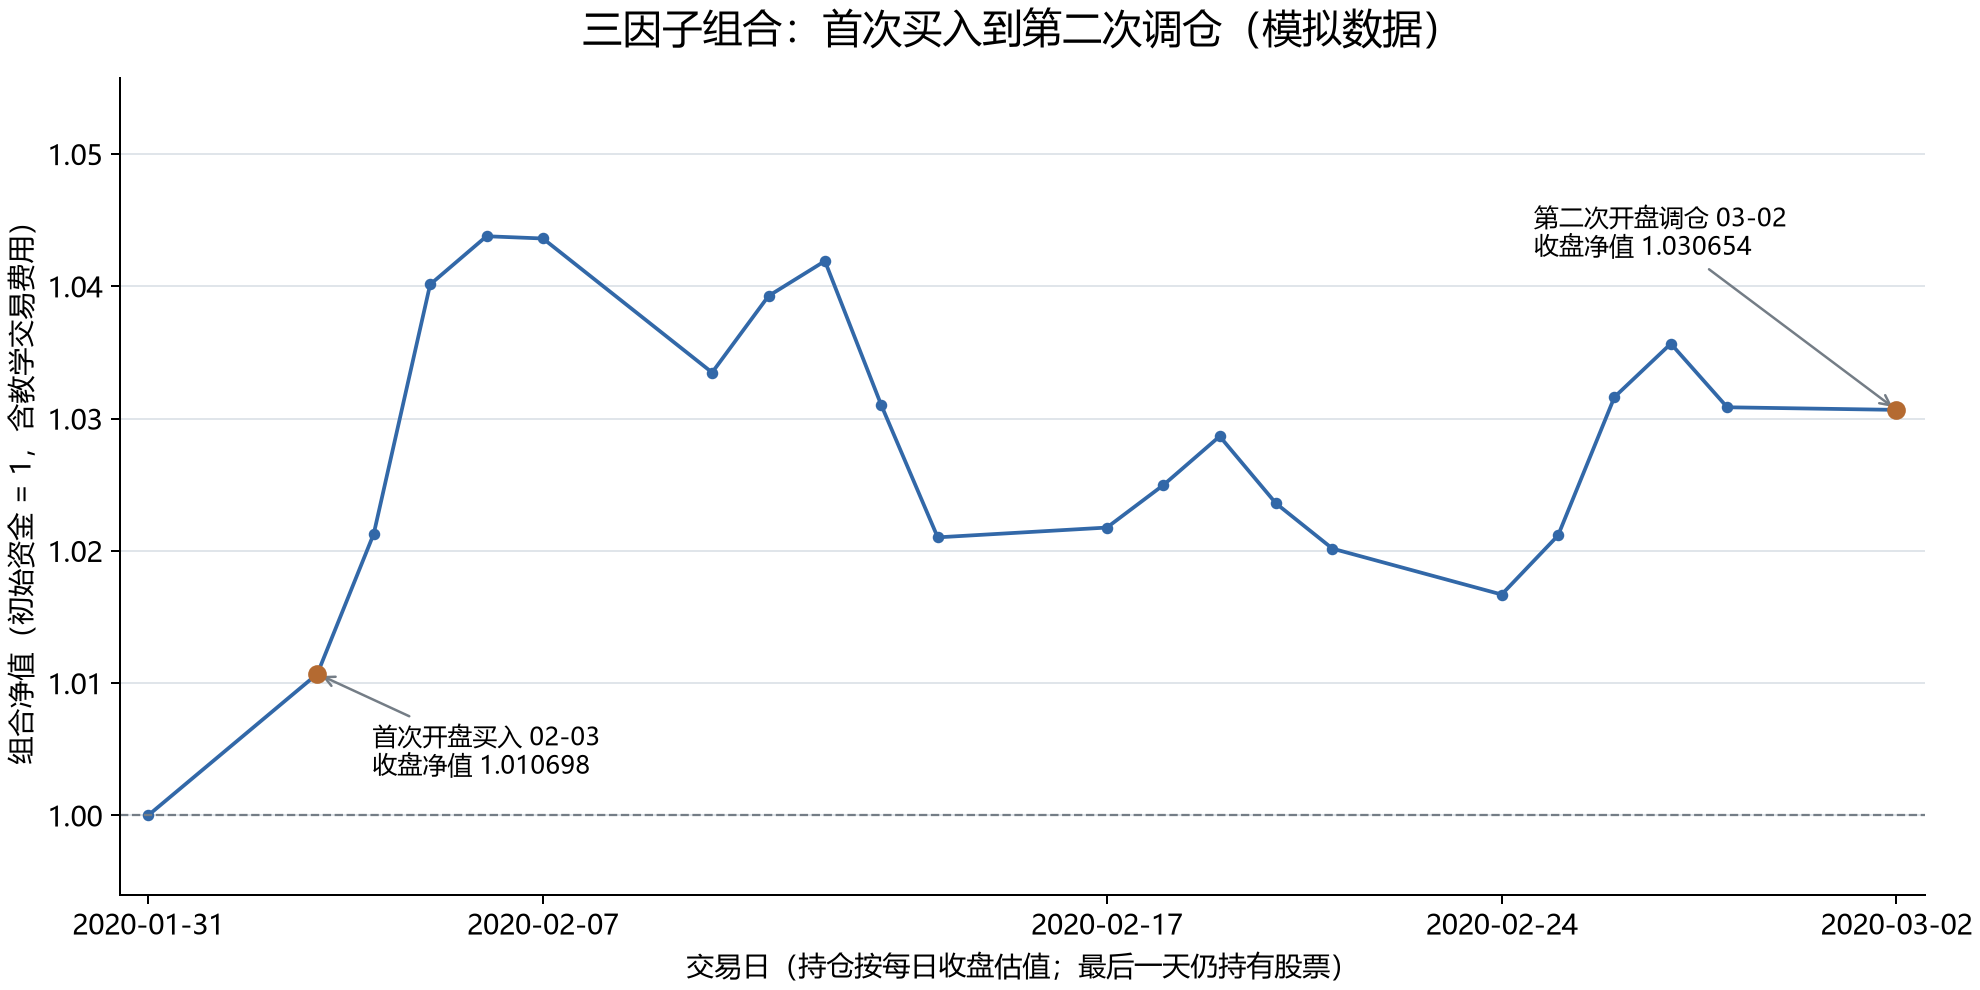

In [8]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / 'runs/first_demo_20261107/lesson14_daily_rebalance/daily_nav.png')))

## 运行复核

以上实现已在干净内核中按顺序执行；执行状态记录在仓库的 [Notebook 校验记录](../../publication/notebook_validation.json)。代码中的数据身份、费用和成交假设仍然适用，运行成功只验证对应实现。